<a href="https://colab.research.google.com/github/eduardoj14/Classificador-de-RG/blob/main/Projeto_rgs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
# 1. IMPORTANDO AS BIBLIOTECAS

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.feature import hog

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [60]:

# 2. LOCALIZANDO E CONFERINDO O DATASET

BASE_DIR = Path("/content/arquivos_rg")

CLASSES = ["rg_antigo", "rg_novo", "invalidos"]
EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

LIMITE_POR_CLASSE = 100
TAMANHO = (64, 64)
META_RECALL = 0.97

dados = []

for classe in CLASSES:
    pasta = BASE_DIR / classe

    if not pasta.is_dir():
        raise FileNotFoundError(
            f"Pasta não encontrada: {pasta}"
        )

    arquivos = sorted(
        arquivo for arquivo in pasta.rglob("*")
        if arquivo.is_file()
        and arquivo.suffix.lower() in EXTENSOES
    )

    if len(arquivos) < LIMITE_POR_CLASSE:
        raise ValueError(
            f"A pasta {classe} tem apenas {len(arquivos)} "
            f"arquivos. São necessários pelo menos 100."
        )

    # Seleção reproduzível de 100 imagens por classe
    rng = np.random.default_rng(42 + CLASSES.index(classe))
    indices = rng.choice(
        len(arquivos),
        size=LIMITE_POR_CLASSE,
        replace=False
    )

    for indice in sorted(indices):
        dados.append({
            "arquivo": str(arquivos[indice]),
            "classe": classe
        })

df = pd.DataFrame(dados)

print("Total de imagens selecionadas:", len(df))
display(
    df["classe"].value_counts()
      .reindex(CLASSES)
      .rename_axis("Classe")
      .reset_index(name="Quantidade")
)

Total de imagens selecionadas: 300


,Classe,Quantidade
0,rg_antigo,100
1,rg_novo,100
2,invalidos,100


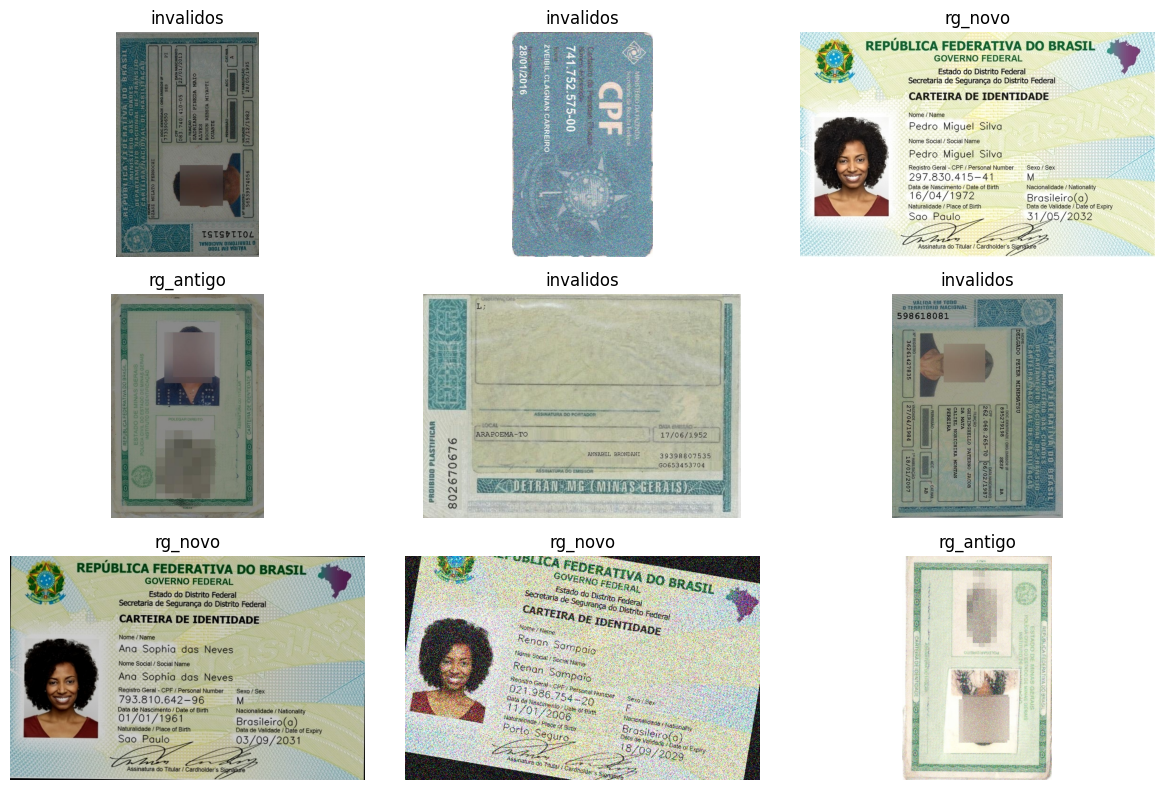

In [61]:
# 3. VISUALIZANDO ALGUMAS IMAGENS

amostra = df.sample(n=9, random_state=42)

plt.figure(figsize=(12, 8))

for i, (_, linha) in enumerate(amostra.iterrows(), start=1):
    imagem = cv2.imread(linha["arquivo"])

    if imagem is None:
        continue

    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i)
    plt.imshow(imagem)
    plt.title(linha["classe"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [62]:
# 4. PREPARAÇÃO DAS IMAGENS E EXTRAÇÃO DE FEATURES

imagens_processadas = []
rotulos = []
caminhos_validos = []
erros = 0

for _, linha in df.iterrows():

    imagem = cv2.imread(linha["arquivo"])

    if imagem is None:
        erros += 1
        continue

    imagem = cv2.cvtColor(
        imagem, cv2.COLOR_BGR2GRAY
    )

    imagem = cv2.resize(imagem, TAMANHO)

    # HOG utiliza bordas, contornos e direções dos gradientes
    caracteristicas_hog = hog(
        imagem,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # Reduz a imagem para 32x32 e utiliza os pixels normalizados
    imagem_reduzida = cv2.resize(imagem, (32, 32))
    caracteristicas_pixels = (
        imagem_reduzida.astype("float32").flatten() / 255.0
    )

    # Combina pixels e HOG
    vetor = np.concatenate([
        caracteristicas_pixels,
        caracteristicas_hog
    ])

    imagens_processadas.append(vetor)
    rotulos.append(linha["classe"])
    caminhos_validos.append(linha["arquivo"])

X = np.array(imagens_processadas, dtype=np.float32)
y = np.array(rotulos)

df_final = pd.DataFrame({
    "arquivo": caminhos_validos,
    "classe": y
})

print("\nImagens processadas:", len(y))
print("Imagens com erro de leitura:", erros)
print("\nQuantidade válida por classe:")

contagem = (
    df_final["classe"].value_counts()
    .reindex(CLASSES, fill_value=0)
)

display(
    contagem.rename_axis("Classe")
    .reset_index(name="Quantidade")
)

if len(y) != 300 or any(contagem != 100):
    raise ValueError(
        "O dataset final precisa conter 300 imagens válidas, "
        "com exatamente 100 por classe."
    )

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Extração de características concluída!")


Imagens processadas: 300
Imagens com erro de leitura: 0

Quantidade válida por classe:


,Classe,Quantidade
0,rg_antigo,100
1,rg_novo,100
2,invalidos,100


Formato de X: (300, 2788)
Formato de y: (300,)
Extração de características concluída!


In [63]:
# 5. SEPARAÇÃO DOS DADOS

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nImagens de treinamento:", len(y_treino))
print("Imagens de teste:", len(y_teste))

print("\nDistribuição do conjunto de teste:")
display(
    pd.Series(y_teste)
    .value_counts()
    .reindex(CLASSES)
    .rename_axis("Classe")
    .reset_index(name="Quantidade")
)


Imagens de treinamento: 240
Imagens de teste: 60

Distribuição do conjunto de teste:


,Classe,Quantidade
0,rg_antigo,20
1,rg_novo,20
2,invalidos,20


In [64]:
# 6. CONFIGURAÇÃO DOS TRÊS MODELOS

modelos_parametros = {
    "SVM": (
        Pipeline([
            ("escala", StandardScaler()),
            ("modelo", SVC(class_weight="balanced"))
        ]),
        {
            "modelo__C": [1, 10, 100],
            "modelo__gamma": ["scale", 0.001, 0.0001],
            "modelo__kernel": ["rbf"]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 20],
            "min_samples_leaf": [1, 2],
            "max_features": ["sqrt"]
        }
    ),

    "KNN": (
        Pipeline([
            ("escala", StandardScaler()),
            ("modelo", KNeighborsClassifier())
        ]),
        {
            "modelo__n_neighbors": [3, 5, 7, 9],
            "modelo__weights": ["uniform", "distance"],
            "modelo__p": [1, 2]
        }
    )
}

print("\nModelos preparados:", list(modelos_parametros.keys()))


Modelos preparados: ['SVM', 'Random Forest', 'KNN']


In [65]:
# 7. AJUSTE DE PARÂMETROS E TREINAMENTO

validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelos_treinados = {}
previsoes = {}
resultados = {}
parametros_escolhidos = {}

for nome, (modelo, parametros) in modelos_parametros.items():

    print(f"\n{'=' * 55}")
    print("Ajustando modelo:", nome)

    busca = GridSearchCV(
        estimator=modelo,
        param_grid=parametros,
        scoring="recall_macro",
        cv=validacao,
        n_jobs=-1,
        refit=True
    )

    # Ajuste usando somente os dados de treinamento
    busca.fit(X_treino, y_treino)

    melhor_modelo = busca.best_estimator_
    y_previsto = melhor_modelo.predict(X_teste)

    modelos_treinados[nome] = melhor_modelo
    previsoes[nome] = y_previsto
    parametros_escolhidos[nome] = busca.best_params_

    resultados[nome] = {
        "Acurácia": accuracy_score(y_teste, y_previsto),
        "Precisão macro": precision_score(
            y_teste, y_previsto,
            labels=CLASSES,
            average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            y_teste, y_previsto,
            labels=CLASSES,
            average="macro",
            zero_division=0
        ),
        "F1-score macro": f1_score(
            y_teste, y_previsto,
            labels=CLASSES,
            average="macro",
            zero_division=0
        )
    }

    print("Melhores parâmetros:", busca.best_params_)
    print("Recall macro na validação cruzada:",
          round(busca.best_score_, 3))

    print("\nRelatório por classe:")
    print(classification_report(
        y_teste,
        y_previsto,
        labels=CLASSES,
        target_names=CLASSES,
        zero_division=0,
        digits=3
    ))


Ajustando modelo: SVM
Melhores parâmetros: {'modelo__C': 1, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
Recall macro na validação cruzada: 1.0

Relatório por classe:
              precision    recall  f1-score   support

   rg_antigo      1.000     1.000     1.000        20
     rg_novo      1.000     1.000     1.000        20
   invalidos      1.000     1.000     1.000        20

    accuracy                          1.000        60
   macro avg      1.000     1.000     1.000        60
weighted avg      1.000     1.000     1.000        60


Ajustando modelo: Random Forest
Melhores parâmetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Recall macro na validação cruzada: 0.971

Relatório por classe:
              precision    recall  f1-score   support

   rg_antigo      0.952     1.000     0.976        20
     rg_novo      1.000     1.000     1.000        20
   invalidos      1.000     0.950     0.974        20

    accuracy         

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [       nan 0.98333333 0.99166667 0.99166667        nan 0.97916667
 0.9875     0.9875            nan 0.97083333 0.975      0.97916667
        nan 0.9625     0.9625     0.96666667]
  warnings.warn(


In [66]:
# 8. COMPARAÇÃO DOS MODELOS

comparacao = pd.DataFrame(resultados).T
comparacao.index.name = "Modelo"
comparacao = comparacao.reset_index()

recalls_por_modelo = {}

for nome, y_previsto in previsoes.items():

    recalls = recall_score(
        y_teste,
        y_previsto,
        labels=CLASSES,
        average=None,
        zero_division=0
    )

    recalls_por_modelo[nome] = recalls

comparacao["Menor recall"] = [
    min(recalls_por_modelo[nome])
    for nome in comparacao["Modelo"]
]

comparacao = comparacao.sort_values(
    by=["Menor recall", "F1-score macro"],
    ascending=False
).reset_index(drop=True)

print("\nCOMPARAÇÃO FINAL DOS MODELOS:")
display(comparacao.round(3))


COMPARAÇÃO FINAL DOS MODELOS:


,Modelo,Acurácia,Precisão macro,Recall macro,F1-score macro,Menor recall
0,SVM,1.000,1.000,1.000,1.000,1.00
1,Random Forest,0.983,0.984,0.983,0.983,0.95
2,KNN,0.983,0.984,0.983,0.983,0.95


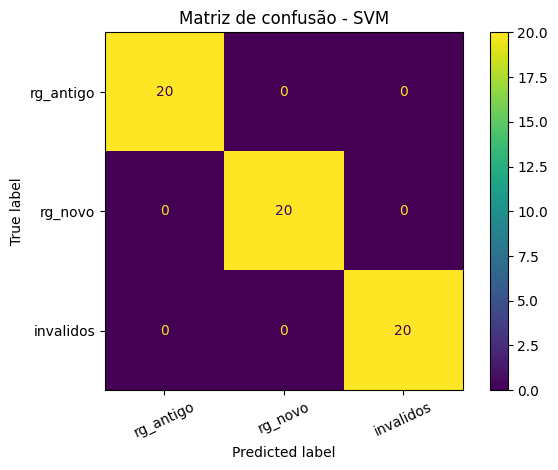

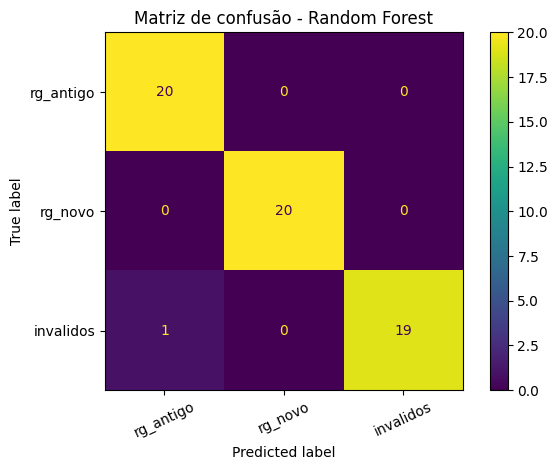

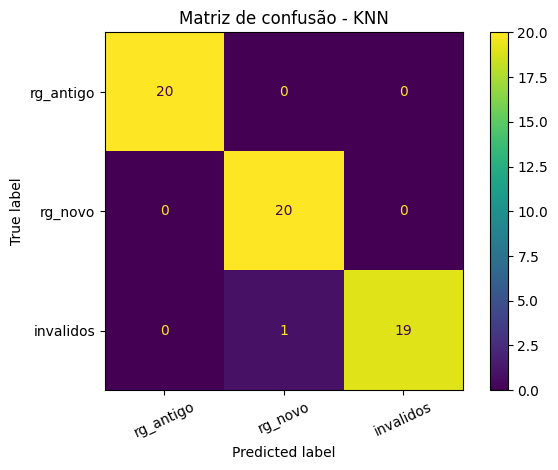

In [67]:
# 9. MATRIZES DE CONFUSÃO

for nome, y_previsto in previsoes.items():

    matriz = confusion_matrix(
        y_teste,
        y_previsto,
        labels=CLASSES
    )

    exibicao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES
    )

    exibicao.plot(values_format="d")
    plt.title(f"Matriz de confusão - {nome}")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

In [68]:
# 10. VERIFICAÇÃO DA META DE RECALL

print("\nVERIFICAÇÃO DA META DE 97%:")

modelos_que_atingiram = []

for nome, recalls in recalls_por_modelo.items():

    print(f"\nModelo: {nome}")
    todos_atingiram = True

    for classe, recall in zip(CLASSES, recalls):

        atingiu = recall >= META_RECALL
        todos_atingiram = todos_atingiram and atingiu

        status = "ATINGIU" if atingiu else "NÃO ATINGIU"

        print(
            f"{classe}: {recall:.1%} — {status}"
        )

    print(
        "Meta em todas as classes:",
        "SIM" if todos_atingiram else "NÃO"
    )

    if todos_atingiram:
        modelos_que_atingiram.append(nome)


VERIFICAÇÃO DA META DE 97%:

Modelo: SVM
rg_antigo: 100.0% — ATINGIU
rg_novo: 100.0% — ATINGIU
invalidos: 100.0% — ATINGIU
Meta em todas as classes: SIM

Modelo: Random Forest
rg_antigo: 100.0% — ATINGIU
rg_novo: 100.0% — ATINGIU
invalidos: 95.0% — NÃO ATINGIU
Meta em todas as classes: NÃO

Modelo: KNN
rg_antigo: 100.0% — ATINGIU
rg_novo: 100.0% — ATINGIU
invalidos: 95.0% — NÃO ATINGIU
Meta em todas as classes: NÃO
